In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1. Create a realistic vehicle dataset (similar to practical EDA tasks)

data = {
    'car_model': ['Sedan A', 'SUV B', 'Hatchback C', 'Sedan A', 'SUV B', 'Hatchback C', 'SUV B', 'Sedan A'],
    'year': [2018, 2020, 2015, 2019, 2022, 2017, 2021, 2016],
    'km_driven': [50000, 30000, 120000, 40000, 15000, 100000, 70000, 95000],
    'engine_cc': [1600, 2500, 1300, 1600, 2000, 1800, 2400, 1500],
    'previous_owners': [1, 1, 3, 1, 1, 4, 2, 3],
    'price': [15000, 28000, 8000, 17000, 35000, 50000, 30000, 12000]
}

df = pd.DataFrame(data)
print("--- Initial Raw DataFrame ---")
display(df.head())

# 2. Feature Creation: Calculate the age of the car based on the reference year 2026

df['car_age'] = 2026 - df['year']

# 3. Select numerical features for scaling and extraction

numeric_features = ['km_driven', 'engine_cc', 'previous_owners', 'car_age']
X = df[numeric_features]

# 4. Critical Step: Feature Scaling (Standardization)
# Standardizing features is mandatory before applying PCA or distance-based algorithms 
# to ensure all variables have a mean of 0 and a variance of 1, preventing large-scale 
# features (like km_driven) from dominating smaller-scale features.

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("\n--- Standardized Data (First 3 rows) ---")
print(X_scaled[:3])

# 5. Feature Extraction via PCA (Dimensionality Reduction)
# Compressing the 4 numerical features down to 2 principal components (orthogonal axes)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("\n--- New Reduced Dimensions (PCA Output, First 3 rows) ---")
print(X_pca[:3])

# 6. Evaluation: Check the Explained Variance Ratio

print("\nExplained Variance Ratio per Component:", pca.explained_variance_ratio_)
total_variance_explained = sum(pca.explained_variance_ratio_) * 100
print(f"Total Variance Preserved in Lower-Dimensional Space: {total_variance_explained:.2f}%")

--- Initial Raw DataFrame ---


,car_model,year,km_driven,engine_cc,previous_owners,price
0,Sedan A,2018,50000,1600,1,15000
1,SUV B,2020,30000,2500,1,28000
2,Hatchback C,2015,120000,1300,3,8000
3,Sedan A,2019,40000,1600,1,17000
4,SUV B,2022,15000,2000,1,35000



--- Standardized Data (First 3 rows) ---
[[-0.42966892 -0.58944845 -0.89442719  0.21821789]
 [-1.00256082  1.64425093 -0.89442719 -0.65465367]
 [ 1.57545272 -1.3340149   0.89442719  1.52752523]]

--- New Reduced Dimensions (PCA Output, First 3 rows) ---
[[-0.29716768 -1.11290767]
 [-2.0294098   0.56277547]
 [ 2.67754882 -0.34783004]]

Explained Variance Ratio per Component: [0.76810728 0.18482156]
Total Variance Preserved in Lower-Dimensional Space: 95.29%


In [2]:
import pandas as pd
import numpy as np
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# 1. Load the benchmark Wine dataset (contains 13 features and 3 target classes)

wine = load_wine()
X = wine.data
y = wine.target
feature_names = wine.feature_names

df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

print("--- Initial Wine Dataset Info ---")
print(f"Features shape: {X.shape}, Classes: {np.unique(y)}")

# 2. Critical Step: Train-Test Split to prevent Data Leakage
# Because LDA is supervised, splitting data BEFORE scaling and extraction 
# is mandatory to avoid leaking test labels into the training phase.

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Feature Scaling (Standardization)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Supervised Feature Extraction via LDA
# Note: The maximum number of components in LDA is bounded by (Number of Classes - 1).
# Since we have 3 classes, n_components will automatically be at most 2.

lda = LinearDiscriminantAnalysis(n_components=2)

# Fitting LDA using BOTH training features and training target labels (Supervised)

X_train_lda = lda.fit_transform(X_train_scaled, y_train)
X_test_lda = lda.transform(X_test_scaled)

print("\n--- New Reduced Dimensions (LDA Output Shape) ---")
print(f"Training transformed shape: {X_train_lda.shape}")

# 5. Evaluation: Check Explained Variance Ratio of the linear discriminants

print("\nExplained Variance Ratio per Linear Discriminant:", lda.explained_variance_ratio_)
total_lda_variance = sum(lda.explained_variance_ratio_) * 100
print(f"Total Class-Separability Variance Preserved: {total_lda_variance:.2f}%")

--- Initial Wine Dataset Info ---
Features shape: (178, 13), Classes: [0 1 2]

--- New Reduced Dimensions (LDA Output Shape) ---
Training transformed shape: (142, 2)

Explained Variance Ratio per Linear Discriminant: [0.71429654 0.28570346]
Total Class-Separability Variance Preserved: 100.00%


In [3]:
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 1. Simulate a realistic Industrial IoT dataset (5,000 time-steps, 50 raw sensors)

np.random.seed(42)
n_samples = 5000
n_features = 50

# Generating raw sensor data with completely different scales (e.g., Temperature in C, Pressure in Bar, Vibration in mm/s)

sensor_data = np.random.rand(n_samples, n_features)
sensor_data[:, 0:10] *= 500     # High-range temperature sensors (0 - 500 °C)
sensor_data[:, 10:25] *= 10     # Medium-range pressure sensors (0 - 10 Bar)
sensor_data[:, 25:50] *= 0.05   # Fine vibration micro-sensors (0 - 0.05 mm/s)

# Create a DataFrame

feature_names = [f"sensor_{i+1}" for i in range(n_features)]
df_sensors = pd.DataFrame(sensor_data, columns=feature_names)

# Add a target label: Machine Failure (0 = Healthy, 1 = Imminent Failure)

df_sensors['machine_failure'] = np.random.choice([0, 1], size=n_samples, p=[0.85, 0.15])

X = df_sensors.drop(columns=['machine_failure'])
y = df_sensors['machine_failure']

print("--- Raw Industrial Data Shape ---")
print(f"Original feature dimensions: {X.shape}")

# 2. Critical Step: Feature Scaling (Standardization)
# Mandatory for industrial IoT because raw sensors have vastly different units and magnitudes.
# Without scaling, the temperature sensors (0-500) would completely eclipse the fine vibration sensors (0-0.05).

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Feature Extraction via PCA (Dimensionality Reduction)
# Compressing 50 correlated physical sensors down to 6 principal components (Latent Mechanical Factors)

pca = PCA(n_components=6)
X_extracted = pca.fit_transform(X_scaled)

df_reduced = pd.DataFrame(X_extracted, columns=[f"latent_factor_{i+1}" for i in range(6)])
df_reduced['machine_failure'] = y.values

print("\n--- Extracted Reduced DataFrame Preview ---")
display(df_reduced.head())

# 4. Evaluation: Check the Cumulative Explained Variance

explained_variance = pca.explained_variance_ratio_
total_variance_preserved = sum(explained_variance) * 100

print(f"\nExplained Variance per Latent Component: {np.round(explained_variance * 100, 2)}%")
print(f"Total Information Retained in Lower Space: {total_variance_preserved:.2f}%")

--- Raw Industrial Data Shape ---
Original feature dimensions: (5000, 50)

--- Extracted Reduced DataFrame Preview ---


,latent_factor_1,latent_factor_2,latent_factor_3,latent_factor_4,latent_factor_5,latent_factor_6,machine_failure
0,1.259421,-1.615119,1.869816,1.150963,-1.112555,0.329564,1
1,-0.150898,0.817665,-0.213169,1.356464,-1.774845,-0.028763,0
2,-1.241556,-0.571330,-0.664988,-1.632145,0.606205,-1.461328,0
3,-0.579727,1.355277,0.625975,-0.056904,1.090886,1.318462,0
4,-0.468338,1.359074,-0.264280,0.191657,-0.460028,2.139507,0



Explained Variance per Latent Component: [2.38 2.35 2.31 2.28 2.27 2.26]%
Total Information Retained in Lower Space: 13.85%


In [9]:
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 1. Simulate Telecom Customer Dataset (e.g., call duration, data usage, complaints, contract length)

np.random.seed(42)
n_samples = 2000
data = {
    'monthly_charges': np.random.uniform(20, 120, n_samples),
    'total_data_gb': np.random.uniform(1, 50, n_samples),
    'customer_service_calls': np.random.randint(0, 10, n_samples),
    'tenure_months': np.random.randint(1, 72, n_samples),
    'roaming_charges': np.random.uniform(0, 30, n_samples)
}
df = pd.DataFrame(data)

# 2. Standardization (Mandatory for distance/variance-based algorithms)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

# 3. Feature Extraction via PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)


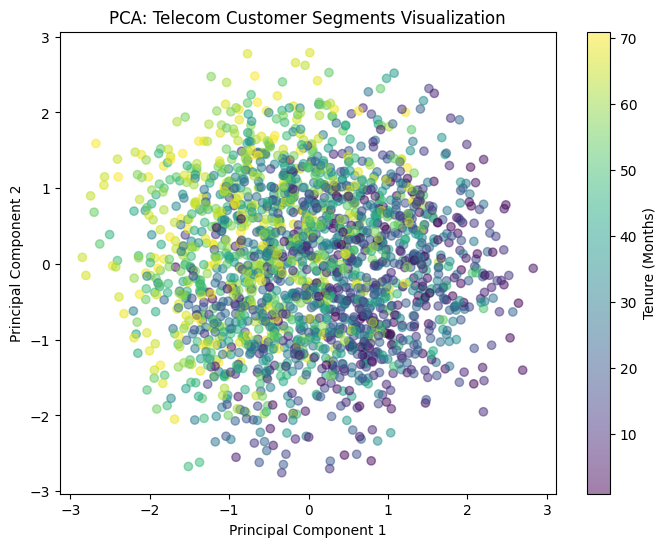

In [8]:
# 4. Visualization: Scatter plot of reduced customer features

import matplotlib.pyplot as plt
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.5, c=df['tenure_months'], cmap='viridis')
plt.title('PCA: Telecom Customer Segments Visualization')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.colorbar(label='Tenure (Months)')
plt.show()

In [11]:
import numpy as np
import pandas as pd
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

# 1. Simulate E-commerce User Behaviour Dataset (15 high-dimensional features)

np.random.seed(10)
n_samples = 1500
X = np.random.rand(n_samples, 15) # 15 behavioral metrics

# 2. Scale the features

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Non-linear Dimensionality Reduction using t-SNE for Visualization

tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_tsne = tsne.fit_transform(X_scaled)



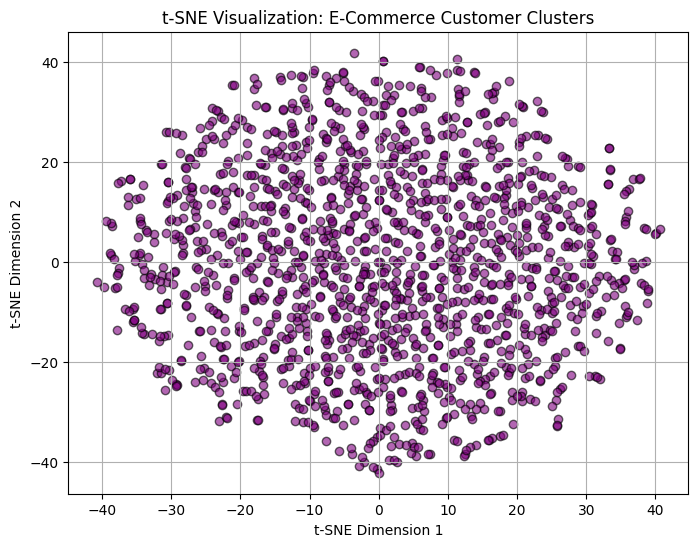

In [10]:
# 4. Visualization: 2D Cluster Mapping

import matplotlib.pyplot as plt
plt.figure(figsize=(8, 6))
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c='purple', alpha=0.6, edgecolors='k')
plt.title('t-SNE Visualization: E-Commerce Customer Clusters')
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.grid(True)
plt.show()

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model

# 1. Simulate flattened image data (e.g., 5000 samples, 784 pixels)

np.random.seed(42)
X_train = np.random.rand(5000, 784)

# Add noise to simulate real-world noisy images

X_train_noisy = X_train + 0.3 * np.random.normal(loc=0.0, scale=1.0, size=X_train.shape)
X_train_noisy = np.clip(X_train_noisy, 0., 1.)

# 2. Build Autoencoder Architecture (Encoder -> Bottleneck -> Decoder)

input_img = Input(shape=(784,))

# Encoder (Dimensionality Reduction to 32 latent features)

encoded = Dense(128, activation='relu')(input_img)
encoded = Dense(32, activation='relu')(encoded) # Latent / Bottleneck Space

# Decoder (Reconstruction)

decoded = Dense(128, activation='relu')(encoded)
decoded = Dense(784, activation='sigmoid')(decoded)

autoencoder = Model(input_img, decoded)
autoencoder.compile(optimizer='adam', loss='binary_crossentropy')

# 3. Train the model (short run for demonstration)

autoencoder.fit(X_train_noisy, X_train, epochs=3, batch_size=256, shuffle=True)


W0000 00:00:1793926791.735181   29397 cpu_allocator_impl.cc:82] Allocation of 15680000 exceeds 10% of free system memory.


Epoch 1/3


W0000 00:00:1793926793.990786   29397 cpu_allocator_impl.cc:82] Allocation of 15680000 exceeds 10% of free system memory.


20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 0.6934
Epoch 2/3
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.6931
Epoch 3/3
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.6931


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step


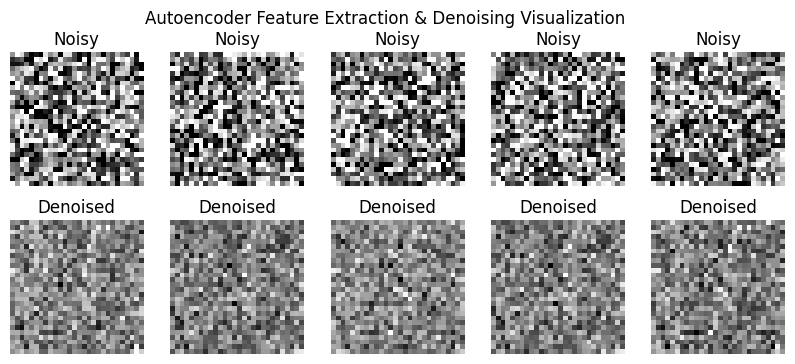

In [12]:
# 4. Visualization: Compare Noisy Input vs. Denoised Reconstruction Output

reconstructed_imgs = autoencoder.predict(X_train_noisy[:5])

plt.figure(figsize=(10, 4))
for i in range(5):
    # Display Noisy Image
    ax = plt.subplot(2, 5, i + 1)
    plt.imshow(X_train_noisy[i].reshape(28, 28), cmap='gray')
    plt.title("Noisy")
    plt.axis('off')
    
    # Display Reconstructed (Denoised) Image from Latent Space
    
    ax = plt.subplot(2, 5, i + 6)
    plt.imshow(reconstructed_imgs[i].reshape(28, 28), cmap='gray')
    plt.title("Denoised")
    plt.axis('off')
plt.suptitle('Autoencoder Feature Extraction & Denoising Visualization')
plt.show()